In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera
from scipy.stats import boxcox
from scipy.stats import boxcox_normmax
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [3]:
df_path = "/content/drive/MyDrive/MBKM/Data/Data Aqi Pollutand dan Meteorologi Bundaran HI.xlsx"
df = pd.read_excel(df_path)

In [4]:
y = df['PM2.5']

X = df[['PM10','SO2','CO','O3','NO2']]

In [5]:
split = int(len(df) * 0.7)

y_train = y.iloc[:split]
y_test  = y.iloc[split:]

X_train = X.iloc[:split]
X_test  = X.iloc[split:]

In [6]:
def adf_test(series):
    result = adfuller(series)
    print("ADF:", result[0])
    print("p-value:", result[1])

print("\nADF train:")
adf_test(y_train)


ADF train:
ADF: -8.046007364438378
p-value: 1.7938567116833802e-12


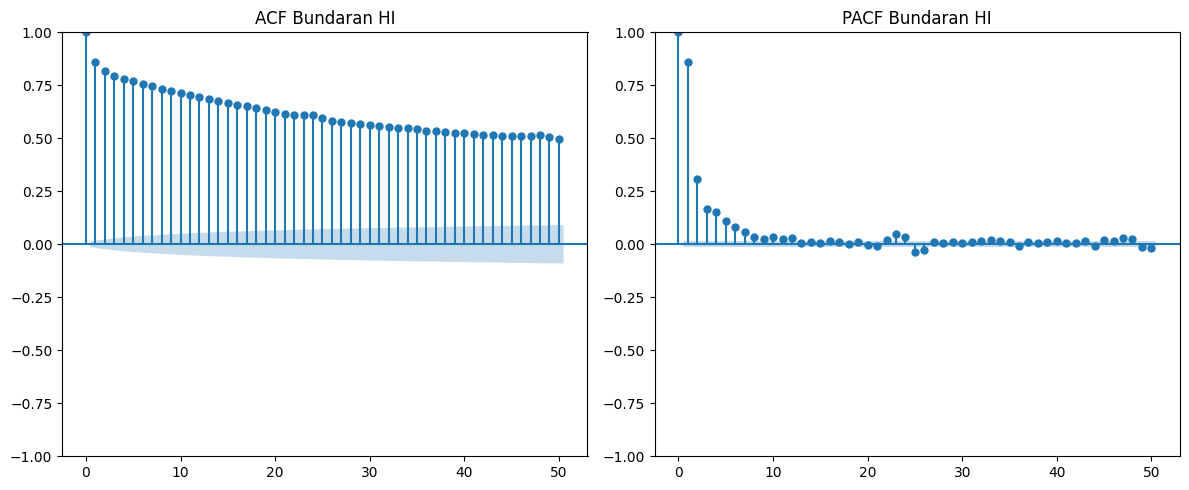

In [7]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plot_acf(y_train, ax=plt.gca(), lags=50)
plt.title("ACF Bundaran HI")

plt.subplot(1, 2, 2)
plot_pacf(y_train, ax=plt.gca(), lags=50, method='ywm')
plt.title("PACF Bundaran HI")

plt.tight_layout()
plt.savefig(
    "/content/drive/MyDrive/MBKM/Analisis ARIMAX/Gambar/Bundaran HI/ACF_PACF_Bundaran HI.jpeg",
    dpi=600,
    format="jpeg",
    bbox_inches="tight"
)
plt.show()

In [8]:
y_diff1 = np.diff(np.diff(y_train))

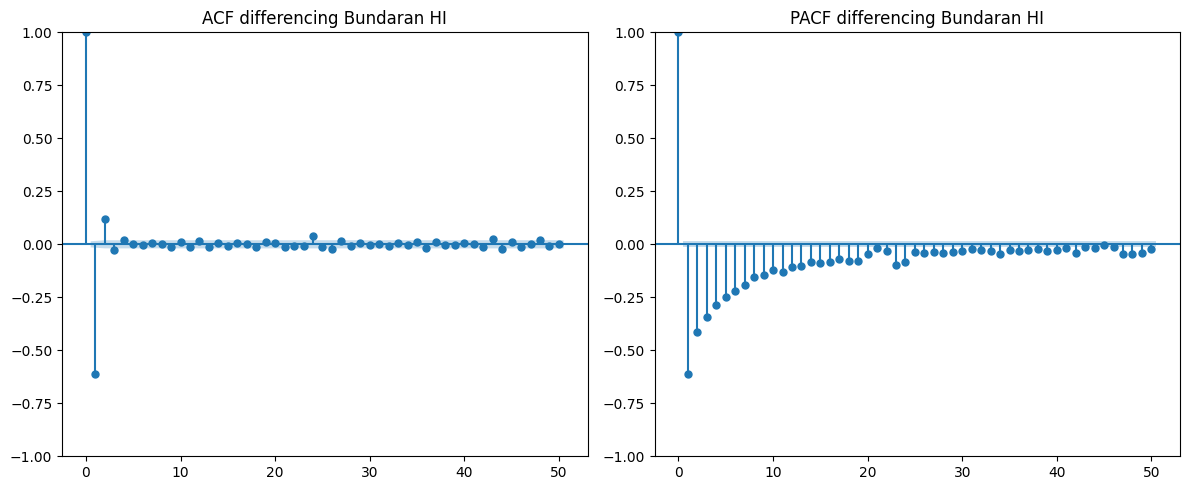

In [9]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plot_acf(y_diff1, ax=plt.gca(), lags=50)
plt.title("ACF differencing Bundaran HI")

plt.tight_layout()
plt.subplot(1, 2, 2)
plot_pacf(y_diff1, ax=plt.gca(), lags=50, method='ywm')
plt.title("PACF differencing Bundaran HI")

plt.tight_layout()
plt.savefig(
    "/content/drive/MyDrive/MBKM/Analisis ARIMAX/Gambar/Bundaran HI/ACF_PACF_differencing_Bundaran HI.jpeg",
    dpi=600,
    format="jpeg",
    bbox_inches="tight"
)
plt.show()

p = 0,
d = 1,
q = {0, 1, 2}